In [28]:
import requests
from pathlib import Path

import osmnx as ox
import geopandas as gpd
import pandas as pd

import matplotlib.pyplot as plt
from matplotlib import patheffects as pe
from matplotlib.lines import Line2D

DATA_DIR = Path("../data/external")
DATA_DIR.mkdir(exist_ok=True)

OUT = Path("../outputs")
OUT.mkdir(exist_ok=True)         # crea la carpeta de salida si no existe

In [ ]:
url = "https://download.geofabrik.de/europe/austria-latest.osm.pbf"
pbf_path = DATA_DIR / "austria-latest.osm.pbf"
CRS_PLOT = "EPSG:31287"

if not pbf_path.exists():
    with requests.get(url, stream=True, timeout=60) as r:
        r.raise_for_status()
        with open(pbf_path, "wb") as f:
            for chunk in r.iter_content(chunk_size=1024 * 1024):
                f.write(chunk)

print(f"{pbf_path.stat().st_size / 1e6:.0f} MB")

In [14]:
austria_path = DATA_DIR / "austria_boundary.gpkg"

if austria_path.exists():
    austria = gpd.read_file(austria_path)
else:
    austria = ox.geocode_to_gdf("Austria").to_crs(CRS_PLOT)
    austria.to_file(austria_path, driver="GPKG")
    austria.plot()

In [15]:
rail_path = DATA_DIR / "austria_rail.gpkg"

if rail_path.exists():
    rail = gpd.read_file(rail_path)
    print(f"Cargado desde disco: {len(rail):,} segmentos")
else:
    # aquí va la lectura del .pbf y el procesamiento
    rail = gpd.read_file(
        pbf_path,
        engine="pyogrio",
        sql="SELECT * FROM lines WHERE railway = 'rail'",
        sql_dialect="OGRSQL",
    )
    print(len(rail), "líneas leídas")

    def tag(series, key):
        """Extrae un valor de other_tags (formato hstore de GDAL)."""
        return series.str.extract(rf'"{key}"=>"([^"]*)"')[0]

    rail["electrified"] = tag(rail["other_tags"], "electrified")
    rail["service"]     = tag(rail["other_tags"], "service")
    rail["usage"]       = tag(rail["other_tags"], "usage")

    # Excluir vías de servicio (apartaderos, playas de vías...)
    rail = rail[rail["service"].isna()].copy()

    rail["is_electrified"] = rail["electrified"].notna() & (rail["electrified"] != "no")
    rail = rail[["name", "usage", "electrified", "is_electrified", "geometry"]].to_crs(CRS_PLOT)

    print(rail["is_electrified"].value_counts())
    print(rail["usage"].value_counts(dropna=False).head())
    rail.to_file(rail_path, driver="GPKG")

Cargado desde disco: 29,908 segmentos


In [16]:
# roads_path = DATA_DIR / "austria_motorways.gpkg"

# if roads_path.exists():
#     roads = gpd.read_file(roads_path)
#     print(f"Cargado desde disco: {len(roads):,} segmentos")
# else:
#     roads = gpd.read_file(
#         pbf_path,
#         engine="pyogrio",
#         sql="SELECT * FROM lines WHERE highway = 'motorway'",
#         sql_dialect="OGRSQL",
#     )

# # 'ref' no es columna propia en la capa lines, está en other_tags
# def tag(series, key):
#     return series.str.extract(rf'"{key}"=>"([^"]*)"')[0]

# roads["ref"] = tag(roads["other_tags"], "ref")

# roads = roads[["name", "ref", "geometry"]].to_crs(CRS_PLOT)
# print(f"{len(roads):,} segmentos de autobahn")
# roads.to_file(roads_path, driver="GPKG")

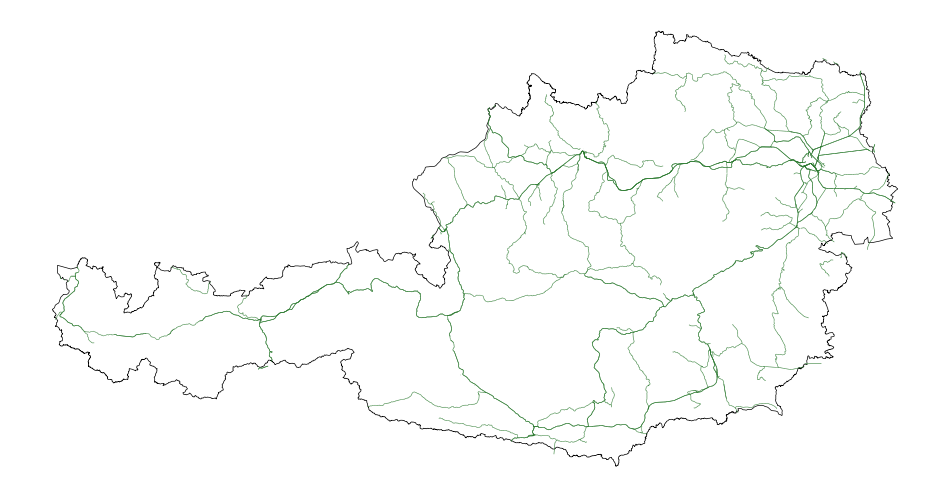

In [17]:
fig, ax = plt.subplots(figsize=(12, 7))
austria.boundary.plot(ax=ax, color="black", linewidth=0.5)
# roads.plot(ax=ax, color="#b0413e", linewidth=0.4)
rail.plot(ax=ax, color="#2e7d32", linewidth=0.4)
ax.set_axis_off()
plt.show()

In [18]:
print(rail.crs)                          # debe ser EPSG:31287
print(rail.geometry.is_valid.all())      # geometrías válidas
print(rail.geometry.is_empty.sum())      # debe ser 0
print(rail.geom_type.value_counts())     # solo LineString / MultiLineString

# Cuánto de la información viene realmente etiquetada
print(rail["electrified"].value_counts(dropna=False))
print(rail["usage"].value_counts(dropna=False))

EPSG:31287
True
0
LineString    29908
Name: count, dtype: int64
electrified
contact_line    24678
no               5219
NaN                11
Name: count, dtype: int64
usage
main          23076
branch         6160
industrial      356
tourism         206
NaN             102
military          6
test              2
Name: count, dtype: int64


In [19]:
rail_map = rail[rail["usage"].isin(["main", "branch"])].copy()
print(f"{len(rail_map):,} segmentos tras filtrar por usage")

29,236 segmentos tras filtrar por usage


In [20]:
rail_map = gpd.clip(rail_map, austria)
rail_map["length_km"] = rail_map.geometry.length / 1000

total = rail_map["length_km"].sum()
print(f"Total: {total:,.0f} km")
print((rail_map.groupby("is_electrified")["length_km"].sum() / total).round(3))

Total: 7,907 km
is_electrified
False    0.174
True     0.826
Name: length_km, dtype: float64


In [23]:
rail_map = rail_map[rail_map.geom_type.isin(["LineString", "MultiLineString"])].copy()

In [22]:
print(rail_map.geom_type.value_counts())

LineString         29127
Point                 14
MultiLineString        2
Name: count, dtype: int64


In [30]:
# nombre: (lon, lat, desplazamiento_x, desplazamiento_y, alineación)
capitals = {
    "Wien":        (16.3738, 48.2082,  8,  8, "left"),
    "St. Pölten":  (15.6256, 48.2047, -6, 10, "right"),
    "Eisenstadt":  (16.5233, 47.8456,  8, -4, "left"),
    "Linz":        (14.2858, 48.3069,  0, 10, "center"),
    "Salzburg":    (13.0550, 47.8095, -8,  6, "right"),
    "Innsbruck":   (11.4041, 47.2692,  0, 10, "center"),
    "Bregenz":     ( 9.7471, 47.5031,  0, -16, "center"),
    "Klagenfurt":  (14.3050, 46.6247,  0, -16, "center"),
    "Graz":        (15.4395, 47.0707,  8, -12, "left"),
}

cap = gpd.GeoDataFrame(
    {"name": list(capitals.keys())},
    geometry=gpd.points_from_xy(
        [v[0] for v in capitals.values()],
        [v[1] for v in capitals.values()],
    ),
    crs="EPSG:4326",
).to_crs(CRS_PLOT)

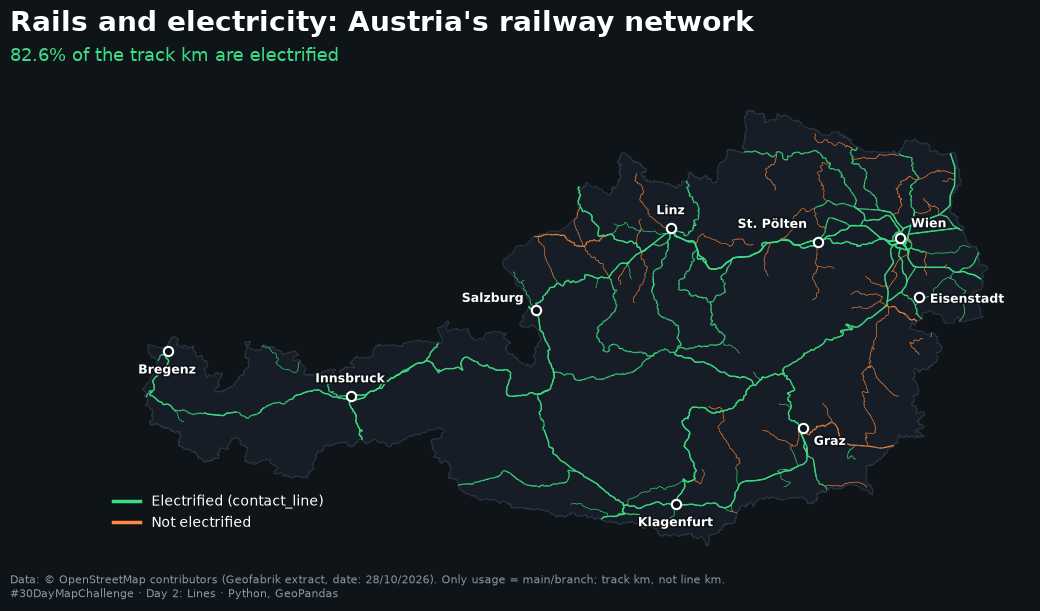

In [41]:
BG = "#0f1419"
GREEN = "#3ddc84"
ORANGE = "#ff8a3d"
GREY = "#2a3440"

fig, ax = plt.subplots(figsize=(12, 7.5), facecolor=BG)
ax.set_facecolor(BG)

# Silueta del país
austria.plot(ax=ax, color="#161d26", edgecolor=GREY, linewidth=0.8)

# Capas: primero lo no electrificado, luego lo electrificado encima
for is_el, color in [(False, ORANGE), (True, GREEN)]:
    for usage, lw in [("branch", 0.5), ("main", 0.9)]:
        sub = rail_map[(rail_map["is_electrified"] == is_el) & (rail_map["usage"] == usage)]
        sub.plot(ax=ax, color=color, linewidth=lw, zorder=3 if is_el else 4)

ax.set_axis_off()

# Título
fig.text(0.05, 0.89, "Rails and electricity: Austria's railway network",
         color="white", fontsize=20, fontweight="bold", ha="left")
fig.text(0.05, 0.85,
         f"{rail_map.loc[rail_map.is_electrified, 'length_km'].sum() / total:.1%} of the track km are electrified",
         color=GREEN, fontsize=13, ha="left")

# Leyenda manual
handles = [Line2D([0], [0], color=GREEN, lw=2.5, label="Electrified (contact_line)"),
           Line2D([0], [0], color=ORANGE, lw=2.5, label="Not electrified")]
ax.legend(handles=handles, loc="lower left", frameon=False,
          labelcolor="white", fontsize=10, bbox_to_anchor=(0.0, 0.05))

# Pie
fig.text(0.05, 0.13,
         "Data: © OpenStreetMap contributors (Geofabrik extract, date: 28/10/2026). Only usage = main/branch; track km, not line km.\n"#
         "#30DayMapChallenge · Day 2: Lines · Python, GeoPandas", color="#8b98a5", fontsize=8, ha="left", va="bottom") #Mapa ilustrativo: la alineación con la Taxonomía UE (act. 6.1/6.2) depende de criterios técnicos y DNSH. 

# Marcador distinto al de la red (anillo blanco hueco), para no confundirlo con otros puntos
cap.plot(ax=ax, facecolor=BG, edgecolor="white", markersize=45, linewidth=1.5, zorder=6)

halo = [pe.withStroke(linewidth=2.5, foreground=BG)]  # contorno oscuro para legibilidad
for _, row in cap.iterrows():
    dx, dy, ha = capitals[row["name"]][2:]
    ax.annotate(row["name"],
                xy=(row.geometry.x, row.geometry.y),
                xytext=(dx, dy), textcoords="offset points",
                color="white", fontsize=9, fontweight="bold",
                ha=ha, zorder=7, path_effects=halo)

handles.append(Line2D([0], [0], marker="o", color="none", markerfacecolor=BG,
                      markeredgecolor="white", markersize=7, label="Capital de Bundesland"))

plt.savefig(OUT / "day02_lines_rail.png", dpi=300, facecolor=BG, bbox_inches="tight")
plt.show()